In [47]:
import numpy as np
from src.datasets import load_examples_mnist
from src.network import Network
from src.optimizers import MomentumOptimizer, AdamOptimizer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import FunctionTransformer, StandardScaler, LabelBinarizer
from sklearn.compose import ColumnTransformer
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [20]:
X, y = load_examples_mnist(n_samples=10000)
X_test, y_test = load_examples_mnist(n_samples=10000,
                                     images_path='data/mnist-handwritten-images/t10k-images-idx3-ubyte/t10k-images-idx3-ubyte',
                                     labels_path='data/mnist-handwritten-images/t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte')

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.9, random_state=1)

sizes = [X_train.shape[1], 30, 10]
activation_functions = ['sigmoid', 'sigmoid']
mini_batch_size = 10
max_epochs = 400

scaler = StandardScaler()
encoder = LabelBinarizer()

X_train_t = scaler.fit_transform(X_train).T
y_train_t = encoder.fit_transform(y_train).T
X_val_t = scaler.transform(X_val).T
y_val_t = encoder.transform(y_val).T

In [3]:
def plot_train_test_accuracy(net: Network, ax=None, **kwargs):
    if ax is None:
        ax = plt.gca()
    training_accuracy = np.array(net.training_accuracy)*100
    test_accuracy = np.array(net.val_accuracy)*100
    epochs = np.arange(len(training_accuracy))
    ax.plot(epochs,training_accuracy,c='blue',label='Training accuracy')
    ax.plot(epochs,test_accuracy,c='red',label='Test accuracy')
    ax.grid(visible=True, axis="both", which="major", linestyle="--", linewidth="0.5")
    ax.set_xlabel("Epochs")
    ax.set_ylabel("Accuracy (%)")
    ax.set_title("Validation Curve")

## Momentum and ADAM

In [73]:
net = Network(sizes, activation_functions, mini_batch_size=mini_batch_size, cost="cross_entropy", init_method="naive",
              max_epochs=max_epochs, random_state=1, verbose=True, monitor_cost=True, monitor_accuracy=True, learning_rate=0.0025)
opts = [MomentumOptimizer(0.9), AdamOptimizer()]
colors = ['red', 'blue']
train_costs = []
val_costs = []
for opt in opts:
    net.set_params(**dict(optimizer=opt))
    net.fit(X_train_t, y_train_t, X_val_t, y_val_t)
    train_costs.append(net.train_cost_cache)
    val_costs.append(net.val_cost_cache)

epoch: 0, cost: 6.1516210141022905
epoch: 100, cost: 1.5436163926827557
epoch: 200, cost: 0.8751544085615227
epoch: 300, cost: 0.5772898870611373
epoch: 0, cost: 3.90405566126664
epoch: 100, cost: 0.003239975442076621
epoch: 133, cost: 0.0009662667404481306


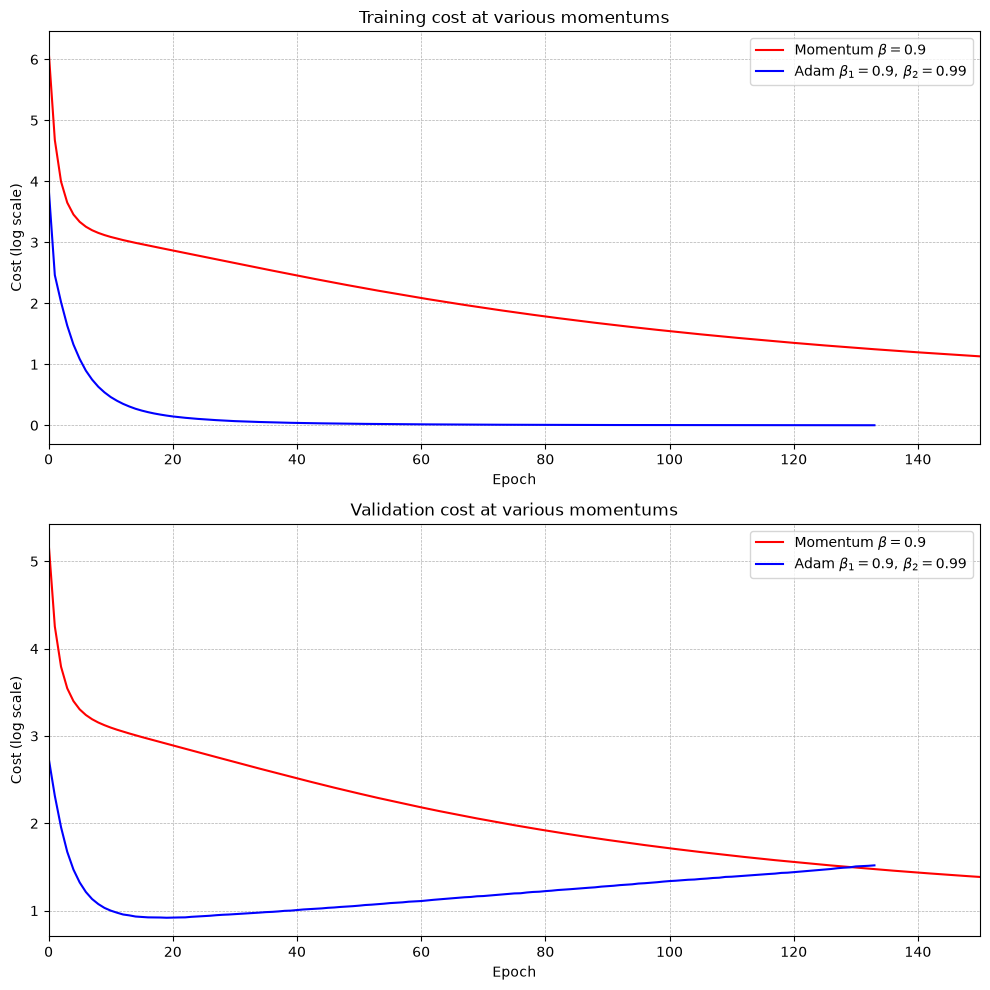

In [77]:
fig,axs = plt.subplots(2,1,figsize=(10,10))
labels = [rf"Momentum $\beta=0.9$",
          rf"Adam $\beta_1=0.9,\, \beta_2=0.99$"]
for color, label, train_cost, val_cost in zip(colors, labels, train_costs, val_costs):
    axs[0].plot(range(len(train_cost)), train_cost, '-', c=color, label=label, mfc=color, mec='k')
    axs[1].plot(range(len(val_cost)), val_cost, '-', c=color, label=label, mfc=color, mec='k')

titles = ['Training cost at various momentums', 'Validation cost at various momentums']
xlims = [(0,150),(0,150)]
yscales = ['linear', 'linear']
for ax,title,xlim,yscale in zip(axs.flatten(), titles, xlims, yscales):
    ax.grid(visible=True, axis="both", which="major", linestyle="--", linewidth="0.5")
    ax.set_xlim(xlim)
    ax.set_xlabel('Epoch')
    ax.set_ylabel("Cost (log scale)")
    ax.set_yscale(yscale)
    ax.legend()
    ax.set_title(title)

plt.tight_layout()
plt.show()